In [1]:
import time
import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from xgboost import XGBRegressor

# Load processed data from T04

data_dir = "../../Feature Engineering/data_processed"

data_train = pd.read_csv(
    os.path.join(data_dir, "data_train.csv")
)

data_test = pd.read_csv(
    os.path.join(data_dir, "data_test.csv")
)

print("Train shape:", data_train.shape)
print("Test shape:", data_test.shape)



Train shape: (9995, 135)
Test shape: (2499, 135)


In [2]:
# Separate features and target

target = "price_million"

X_train = data_train.drop(columns=[target])
y_train = data_train[target]

X_test = data_test.drop(columns=[target])
y_test = data_test[target]

# Validate feature consistency

assert list(X_train.columns) == list(X_test.columns), \
    "Train and test features do not match!"

assert not X_train.isna().any().any(), \
    "Training data contains missing values!"

assert not X_test.isna().any().any(), \
    "Testing data contains missing values!"

assert (y_train >= 0).all(), \
    "Training target contains negative prices!"

assert (y_test >= 0).all(), \
    "Testing target contains negative prices!"

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nMissing values:")
print("Train:", X_train.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

print("\nTarget statistics:")
print(y_train.describe())
non_numeric = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

assert len(non_numeric) == 0, \
    f"Non-numeric features found: {non_numeric}"

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_test.to_numpy()).all()

print("Data validation passed!")

X_train: (9995, 134)
X_test: (2499, 134)

Missing values:
Train: 0
Test: 0

Target statistics:
count     9995.000000
mean       513.155361
std        390.178024
min         20.000000
25%        278.000000
50%        435.000000
75%        635.000000
max      10900.000000
Name: price_million, dtype: float64
Data validation passed!


In [3]:
# Baseline Random Forest

rf = TransformedTargetRegressor(
    regressor=RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, pred_rf))
rf_mae = mean_absolute_error(y_test, pred_rf)
rf_r2 = r2_score(y_test, pred_rf)

print("Random Forest Baseline")
print("RMSE:", round(rf_rmse, 1), "million VND")
print("MAE :", round(rf_mae, 1), "million VND")
print("R2  :", round(rf_r2, 3))

Random Forest Baseline
RMSE: 216.3 million VND
MAE : 83.1 million VND
R2  : 0.733


In [4]:
# Baseline XGBoost

xgb = TransformedTargetRegressor(
    regressor=XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, pred_xgb))
xgb_mae = mean_absolute_error(y_test, pred_xgb)
xgb_r2 = r2_score(y_test, pred_xgb)

print("XGBoost Baseline")
print("RMSE:", round(xgb_rmse, 1), "million VND")
print("MAE :", round(xgb_mae, 1), "million VND")
print("R2  :", round(xgb_r2, 3))

XGBoost Baseline
RMSE: 214.0 million VND
MAE : 84.7 million VND
R2  : 0.739


In [5]:
# Hyperparameter tuning

searches = {
    "rf": (
        TransformedTargetRegressor(
            regressor=RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            ),
            func=np.log1p,
            inverse_func=np.expm1
        ),
        {
            "regressor__n_estimators": [200, 400, 600],
            "regressor__max_depth": [None, 15, 25],
            "regressor__min_samples_leaf": [1, 2, 4],
            "regressor__max_features": ["sqrt", 0.5, 1.0]
        }
    ),

    "xgb": (
        TransformedTargetRegressor(
            regressor=XGBRegressor(
                random_state=42,
                n_jobs=-1
            ),
            func=np.log1p,
            inverse_func=np.expm1
        ),
        {
            "regressor__n_estimators": [300, 600, 900],
            "regressor__learning_rate": [0.03, 0.05, 0.1],
            "regressor__max_depth": [4, 6, 8],
            "regressor__subsample": [0.7, 0.9, 1.0],
            "regressor__colsample_bytree": [0.5, 0.8, 1.0]
        }
    )
}

best = {}
tuning_results = {}

for name, (estimator, params) in searches.items():

    print(f"\nTuning {name.upper()}...")

    start_time = time.time()

    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=params,
        n_iter=10,
        cv=3,
        scoring="neg_root_mean_squared_error",
        random_state=42,
        n_jobs=1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best[name] = search.best_estimator_

    tuning_time = (time.time() - start_time) / 60

    tuning_results[name] = {
        "Best Parameters": search.best_params_,
        "CV RMSE": -search.best_score_,
        "Time (minutes)": tuning_time
    }

    print("\nBest parameters:")
    print(search.best_params_)

    print("CV RMSE:", round(-search.best_score_, 2))
    print("Time:", round(tuning_time, 2), "minutes")


Tuning RF...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best parameters:
{'regressor__n_estimators': 200, 'regressor__min_samples_leaf': 1, 'regressor__max_features': 1.0, 'regressor__max_depth': None}
CV RMSE: 211.43
Time: 1.01 minutes

Tuning XGB...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}
CV RMSE: 206.7
Time: 1.93 minutes


In [6]:
# Evaluate tuned models on the test set

tuned_predictions = {}
tuned_metrics = {}

for name, model in best.items():

    pred = model.predict(X_test)

    tuned_predictions[name] = pred

    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mae = mean_absolute_error(y_test, pred)
    r2 = r2_score(y_test, pred)

    tuned_metrics[name] = {
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    }

    print(f"\n{name.upper()} Tuned")
    print("RMSE:", round(rmse, 1), "million VND")
    print("MAE :", round(mae, 1), "million VND")
    print("R2  :", round(r2, 3))


RF Tuned
RMSE: 216.3 million VND
MAE : 83.1 million VND
R2  : 0.733

XGB Tuned
RMSE: 206.9 million VND
MAE : 79.8 million VND
R2  : 0.755


In [7]:
# Compare baseline and tuned models

results = [
    {
        "Model": "Random Forest (baseline)",
        "RMSE": rf_rmse,
        "MAE": rf_mae,
        "R2": rf_r2
    },
    {
        "Model": "Random Forest (tuned)",
        "RMSE": tuned_metrics["rf"]["RMSE"],
        "MAE": tuned_metrics["rf"]["MAE"],
        "R2": tuned_metrics["rf"]["R2"]
    },
    {
        "Model": "XGBoost (baseline)",
        "RMSE": xgb_rmse,
        "MAE": xgb_mae,
        "R2": xgb_r2
    },
    {
        "Model": "XGBoost (tuned)",
        "RMSE": tuned_metrics["xgb"]["RMSE"],
        "MAE": tuned_metrics["xgb"]["MAE"],
        "R2": tuned_metrics["xgb"]["R2"]
    }
]

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))

                   Model    RMSE    MAE    R2
Random Forest (baseline) 216.259 83.089 0.733
   Random Forest (tuned) 216.259 83.089 0.733
      XGBoost (baseline) 213.970 84.677 0.739
         XGBoost (tuned) 206.930 79.752 0.755


In [8]:
# Select the best tuned model based on CV RMSE

best_name = min(
    tuning_results,
    key=lambda name: tuning_results[name]["CV RMSE"]
)

best_model = best[best_name]

print("Selected model:", best_name.upper())
print("CV RMSE:", round(tuning_results[best_name]["CV RMSE"], 2))
print("Best parameters:")
print(tuning_results[best_name]["Best Parameters"])

# Save selected model

joblib.dump(best_model, "best_model.pkl")

# Save test set for T07/T08

X_test.assign(
    price_million=y_test
).to_csv("test_set.csv", index=False)

print("\nModel saved as best_model.pkl")
print("Test set saved as test_set.csv")

Selected model: XGB
CV RMSE: 206.7
Best parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}



Model saved as best_model.pkl
Test set saved as test_set.csv


C:\Users\ACER\AppData\Local\Temp\ipykernel_15292\3915038939.py:21: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_test.assign(


Top 20 important features:
carbrand_grouped_Lexus            0.06482
gearbox_Số sàn                    0.05680
carbrand_grouped_Porsche          0.05317
carmodel_grouped_VF3              0.05111
carbrand_grouped_Mercedes Benz    0.04905
fuel_Xăng                         0.03142
carmodel_grouped_Morning          0.02817
carmodel_grouped_Fadil            0.02736
car_age                           0.02704
carmodel_grouped_Camry            0.02354
carbrand_grouped_BMW              0.02346
carbrand_grouped_Chevrolet        0.02091
fuel_Dầu                          0.01832
carmodel_grouped_Carnival         0.01755
carmodel_grouped_Attrage          0.01641
carmodel_grouped_Innova Cross     0.01625
carbrand_grouped_MG               0.01603
carbrand_grouped_Daewoo           0.01597
carmodel_grouped_Grand i10        0.01558
carbrand_grouped_Audi             0.01450
dtype: float32


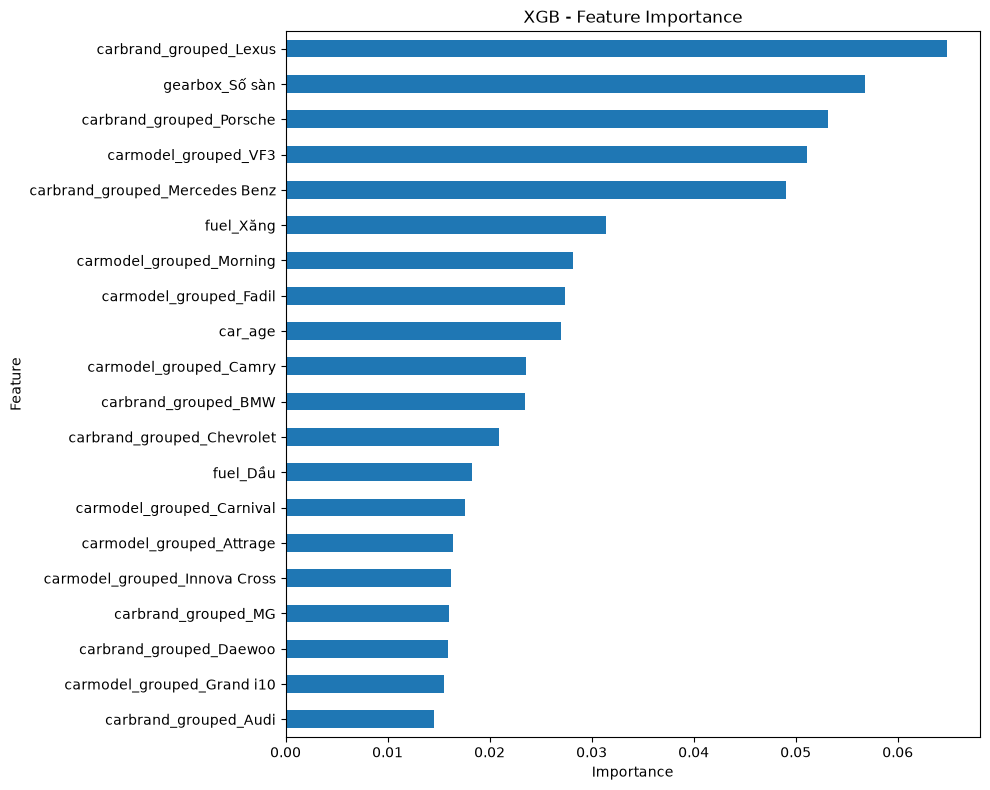

In [9]:
# Feature importance of the selected model

fitted_model = best_model.regressor_

importance = pd.Series(
    fitted_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 20 important features:")
print(importance.head(20).round(5))

# Plot top 20 features

importance.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 8),
    title=f"{best_name.upper()} - Feature Importance"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [10]:
# Reload the saved model and predict 3 test cars

loaded_model = joblib.load("best_model.pkl")

sample_predictions = loaded_model.predict(X_test.head(3))

sanity_check = pd.DataFrame({
    "Actual Price": y_test.head(3).values,
    "Predicted Price": sample_predictions.round(1)
})

print(sanity_check)

   Actual Price  Predicted Price
0         345.0       367.399994
1          25.0        38.000000
2         168.0       134.100006


Top 20 permutation importance:
car_age                           158.780
carbrand_grouped_Mercedes Benz    106.062
carbrand_grouped_Lexus             77.293
carbrand_grouped_Porsche           64.505
gearbox_Số sàn                     50.617
carbrand_grouped_BMW               26.774
carbrand_grouped_Khác              22.022
odo_km                             21.611
carmodel_grouped_Khác              16.806
carbrand_grouped_Audi              12.589
carbrand_grouped_Ford              12.178
carbrand_grouped_Volkswagen        11.090
fuel_Dầu                            8.726
carbrand_grouped_Toyota             7.934
carmodel_grouped_Carnival           7.119
carmodel_grouped_Camry              6.415
km_per_year                         4.887
carmodel_grouped_C Class            4.657
cartype_Hatchback                   4.654
carmodel_grouped_CR V               4.416
dtype: float64


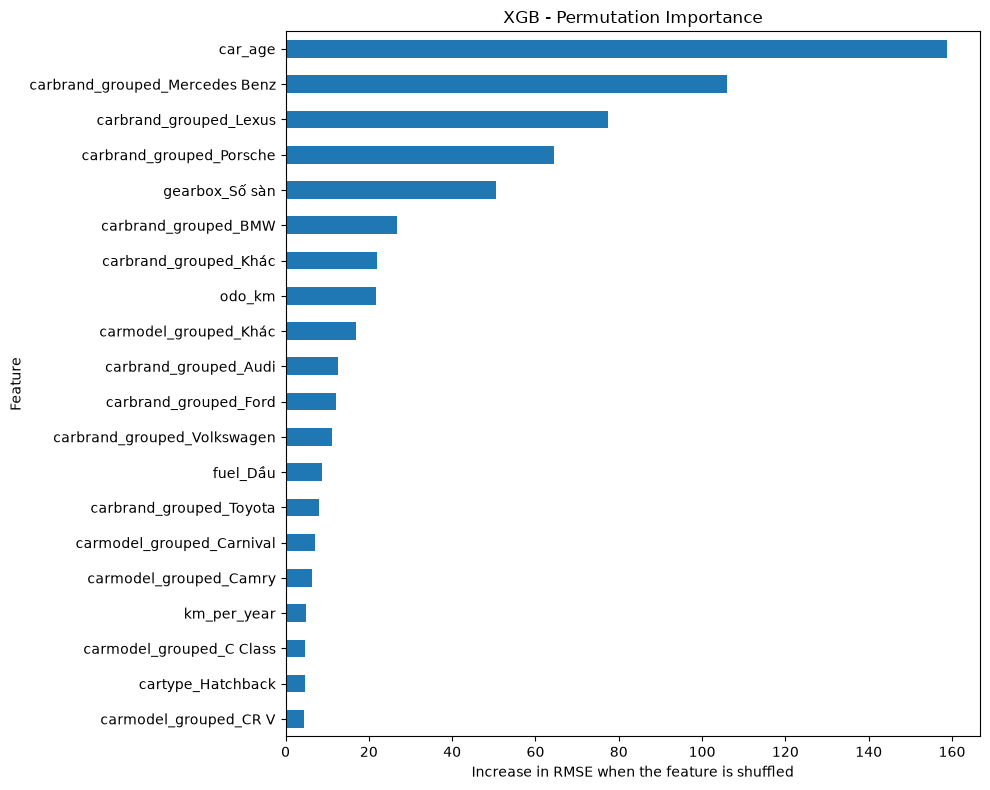

Time: 0.33 minutes


In [11]:
# Permutation importance

start_time = time.time()

perm_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=5,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1
)

perm = pd.Series(
    perm_result.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print("Top 20 permutation importance:")
print(perm.head(20).round(3))

# Plot top 20

perm.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 8),
    title=f"{best_name.upper()} - Permutation Importance"
)

plt.xlabel("Increase in RMSE when the feature is shuffled")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Time:", round((time.time() - start_time) / 60, 2), "minutes")

In [12]:
# Error analysis by price segment

pred = best_model.predict(X_test)

error_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": pred
}, index=y_test.index)

error_df["Absolute Error"] = (
    error_df["Predicted"] - error_df["Actual"]
).abs()

error_df["Percentage Error"] = (
    error_df["Absolute Error"]
    / error_df["Actual"].replace(0, np.nan)
    * 100

)

price_bins = [0, 300, 600, 1000, np.inf]

price_labels = [
    "<= 300",
    "300 - 600",
    "600 - 1000",
    "> 1000"
]

error_df["Price Segment"] = pd.cut(
    error_df["Actual"],
    bins=price_bins,
    labels=price_labels,
    include_lowest=True
)

error_summary = error_df.groupby(
    "Price Segment",
    observed=False
).agg(
    Count=("Absolute Error", "count"),
    MAE=("Absolute Error", "mean"),
    MAPE=("Percentage Error", "mean")
)

print(error_summary.round(1))

               Count    MAE  MAPE
Price Segment                    
<= 300           715   40.3  29.8
300 - 600       1057   47.9  11.0
600 - 1000       500   81.9  10.7
> 1000           227  347.3  20.0


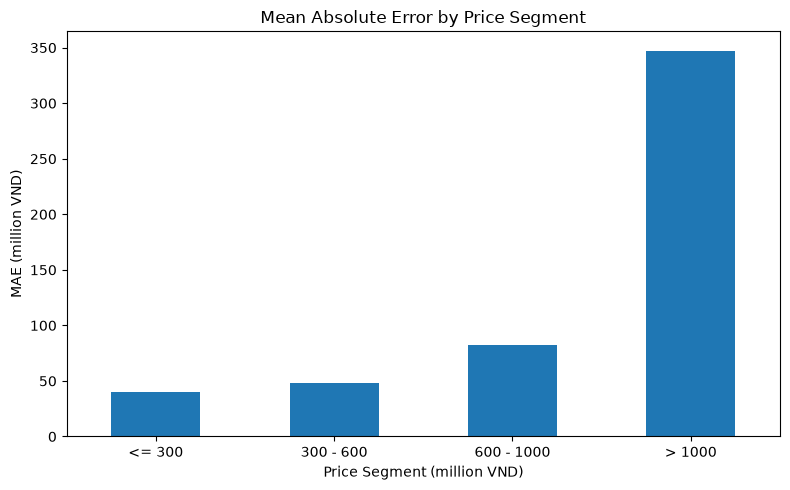

In [13]:
# Plot MAE by price segment

error_summary["MAE"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Mean Absolute Error by Price Segment"
)

plt.xlabel("Price Segment (million VND)")
plt.ylabel("MAE (million VND)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
# Final evaluation summary

final_pred = best_model.predict(X_test)

final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))
final_mae = mean_absolute_error(y_test, final_pred)
final_r2 = r2_score(y_test, final_pred)

print("=" * 45)
print("FINAL MODEL EVALUATION")
print("=" * 45)

print("Selected model:", best_name.upper())
print("RMSE:", round(final_rmse, 2), "million VND")
print("MAE :", round(final_mae, 2), "million VND")
print("R2  :", round(final_r2, 3))

print("\nBest hyperparameters:")
print(tuning_results[best_name]["Best Parameters"])

print("\nCV RMSE:")
print(round(tuning_results[best_name]["CV RMSE"], 2))

FINAL MODEL EVALUATION
Selected model: XGB
RMSE: 206.93 million VND
MAE : 79.75 million VND
R2  : 0.755

Best hyperparameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}

CV RMSE:
206.7


In [15]:
# Save all models for T07

joblib.dump(rf, "rf_baseline.pkl")
joblib.dump(xgb, "xgb_baseline.pkl")

joblib.dump(best["rf"], "rf_tuned.pkl")
joblib.dump(best["xgb"], "xgb_tuned.pkl")

# Save selected model
joblib.dump(best_model, "best_model.pkl")

['best_model.pkl']

In [16]:
from sklearn.pipeline import Pipeline

prep = joblib.load(
    os.path.join(data_dir, "preprocessor.joblib")
)

full_model = Pipeline([
    ("prep", prep),
    ("reg", best_model)
])

joblib.dump(full_model, "best_model_full.pkl")

['best_model_full.pkl']

In [17]:
from sklearn.pipeline import Pipeline

prep = joblib.load(
    os.path.join(data_dir, "preprocessor.joblib")
)

full_model = Pipeline([
    ("prep", prep),
    ("reg", best_model)
])

joblib.dump(full_model, "best_model_full.pkl")

['best_model_full.pkl']

In [18]:
# Save test set for T07/T08

data_test.to_csv("test_set.csv", index=False)